# 🗺️ Notebook 04: Visualizações e Mapeamento Geoespacial Interativo
### Projeto: Análise de Sinistros de Trânsito em Bauru/SP

Neste notebook construímos o mapa dos registros:
1. Filtragem dos registros com coordenadas em um retângulo aproximado ao redor de Bauru;
2. Construção do mapa interativo via **Plotly Express** sobre renderização **Carto Positron**;
3. Estratificação visual de severidade, com os registros sem informação de vítimas à parte;
4. Exportação do arquivo interativo `output/graficos/mapa_acidentes.html`.

In [1]:
import sys
import pandas as pd
import plotly.express as px

sys.path.append('..')
from src.metricas import CORES_SEVERIDADE, ORDEM_SEVERIDADE

df = pd.read_csv('../data/bauru_limpo.csv', sep=';', encoding='utf-8', low_memory=False)
df_geo = df[df['geo_valida']].copy()
print(f"Registros com coordenadas no retângulo: {len(df_geo)} de {len(df)} ({len(df_geo)/len(df)*100:.1f}%)")

Registros com coordenadas no retângulo: 17532 de 19056 (92.0%)


## 1. Configuração do Mapa Temático Interativo

In [2]:
fig = px.scatter_map(
    df_geo,
    lat='lat',
    lon='lon',
    color='severidade_categoria',
    color_discrete_map=CORES_SEVERIDADE,
    category_orders={'severidade_categoria': ORDEM_SEVERIDADE},
    hover_name='tipo_sinistro_simplificado',
    hover_data={
        'lat': False,
        'lon': False,
        'data_sinistro': True,
        'tipo_via': True,
        'logradouro': True,
        'obitos': True,
        'feridos_graves': True,
        'envolve_moto': True
    },
    zoom=11.5,
    center={'lat': -22.3145, 'lon': -49.0587},
    map_style='carto-positron',
    title='Registros de Trânsito em Bauru/SP',
    height=800
)

fig.update_layout(
    margin=dict(l=0, r=0, t=40, b=0),
    legend=dict(
        title=dict(text='Severidade do Sinistro'),
        yanchor='top',
        y=0.98,
        xanchor='left',
        x=0.02,
        bgcolor='rgba(255, 255, 255, 0.9)',
        bordercolor='#cbd5e1',
        borderwidth=1
    )
)

fig.show()

## 2. Mapa Estático por Severidade

O GitHub não exibe o mapa interativo dentro do notebook; esta figura mostra os mesmos pontos em uma imagem.

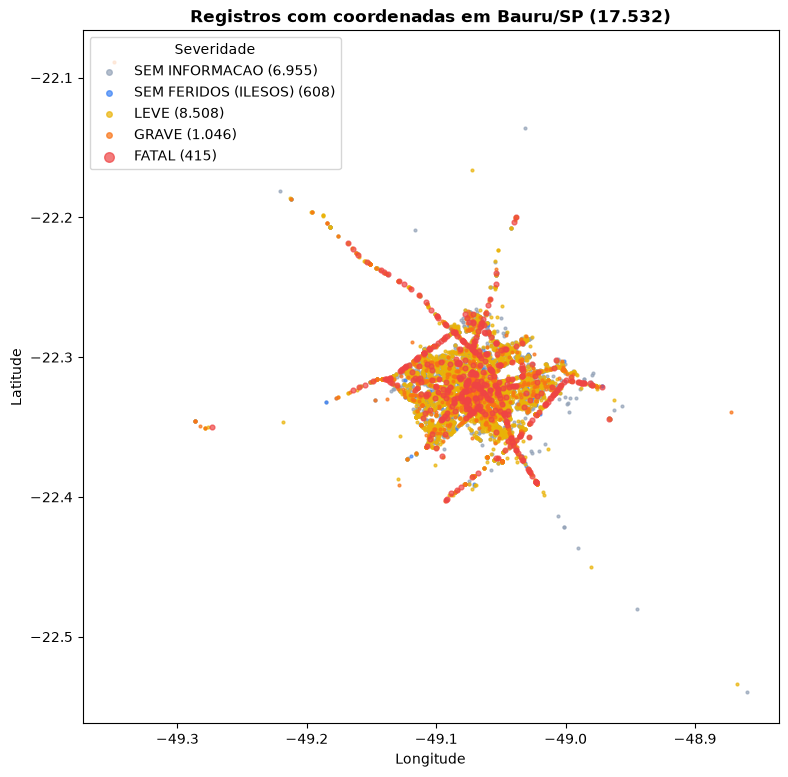

In [3]:
import matplotlib.pyplot as plt
from src.metricas import br

fig_estatica, eixo = plt.subplots(figsize=(10, 9))
# Do menos grave ao fatal, para que os casos graves fiquem por cima
for severidade in ORDEM_SEVERIDADE[::-1]:
    pontos = df_geo[df_geo['severidade_categoria'] == severidade]
    eixo.scatter(
        pontos['lon'], pontos['lat'], c=CORES_SEVERIDADE[severidade],
        s=12 if severidade == 'FATAL' else 4, alpha=0.7, label=f"{severidade} ({br(len(pontos))})",
    )
eixo.set_aspect(1.08)  # Compensa a escala da longitude na latitude de Bauru
eixo.set_title(f"Registros com coordenadas em Bauru/SP ({br(len(df_geo))})", fontweight='bold')
eixo.set_xlabel('Longitude')
eixo.set_ylabel('Latitude')
eixo.legend(title='Severidade', loc='upper left', markerscale=2)
plt.show()

## 3. Exportação do Artefato Interativo HTML

In [4]:
import os

saida_mapa = '../output/graficos/mapa_acidentes.html'
os.makedirs('../output/graficos', exist_ok=True)
fig.write_html(saida_mapa)
print(f"Mapa geoespacial interativo exportado com sucesso para {saida_mapa}!")

Mapa geoespacial interativo exportado com sucesso para ../output/graficos/mapa_acidentes.html!
